# CNN Baseline for AHCD

Task 1 of the updated training plan: train a basic CNN with two convolutional blocks from random weights to recognize 28 Arabic letters. Reuse the published training and validation split.

The code follows the supplied P5.2 MLP and CNN Colab example using TensorFlow/Keras Sequential, Conv2D, MaxPooling2D, Flatten, Dense, compile and fit. The input size and number of classes are adapted to AHCD. Detailed code comments explain the steps.

Only validation results are produced here. Compare the five configurations on validation data before the team's later final test evaluation.

This updated baseline excludes completely blank fitting images following AHCD_EDA.ipynb. Validation membership is unchanged. This run saves separately in results/.

In [1]:
# Standard libraries handle shared file locations, settings and elapsed time.
from pathlib import Path
import json
from time import perf_counter

# Use TensorFlow/Keras, matching the CNN teaching example.
# NumPy loads arrays, pandas displays tables, and Matplotlib draws the figures.
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from IPython.display import display

# Clear any earlier Keras model before building a fresh baseline.
# set_random_seed seeds Python, NumPy and TensorFlow together.
tf.keras.backend.clear_session()
seed = 42
tf.keras.utils.set_random_seed(seed)

# Enable deterministic operations to help repeat this run in the same environment.
# Exact numerical agreement across different hardware or package versions is not guaranteed.
tf.config.experimental.enable_op_determinism()

# Define the output location once for plots, tables and the saved model.
output_folder = Path("results")
output_folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
print("TensorFlow version:", tf.__version__)
print("Keras version:", tf.keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1


## 1. Load the shared data

- Shared files are included in the GitHub handover. No personal Downloads path or Kaggle credentials are required.
- Stored images are upright unsigned integer arrays in channel first format `(N, 1, 32, 32)`.
- Move the channel axis to obtain Keras input format `(N, 32, 32, 1)`, then scale once into 0 to 1.
- Reuse the saved row indices for every model. Do not create another validation split.

In [2]:
# Run this notebook from the 04_neural-networks/keras folder.
shared_folder = Path("../../data/ahcd/shared")

# Context managers close the compressed files after reading their numeric arrays.
# allow_pickle=False avoids loading pickled Python objects.
with np.load(shared_folder / "training_data.npz", allow_pickle=False) as data:

    # Move the channel axis only. This does not rotate or transpose the image itself.
    # The prepared images are already upright and must not be reoriented again.
    stored_images = data["images"]
    images = np.moveaxis(stored_images, 1, -1)
    images = images.astype(np.float32) / 255.0

    # Sparse categorical cross entropy expects integer class indices from 0 to 27.
    labels = data["labels"].astype(np.int64)

with np.load(shared_folder / "split_indices.npz", allow_pickle=False) as split:
    train_indices = split["train_indices"]
    validation_indices = split["validation_indices"]

# JSON keys are strings, so original class numbers are accessed using str(class_id).
label_mapping = json.loads((shared_folder / "label_mapping.json").read_text())

# Check the number of images, height, width and grayscale channels.
# Stop if values or labels are inconsistent with the agreed shared data format.
assert images.shape == (13440, 32, 32, 1)

assert np.isfinite(images).all() and images.min() >= 0 and images.max() <= 1

assert set(np.unique(labels)) == set(range(28))

# Fitting and validation rows must be disjoint and cover all original training rows once.
assert np.intersect1d(train_indices, validation_indices).size == 0
all_split_indices = np.concatenate([train_indices, validation_indices])

assert np.array_equal(np.sort(all_split_indices), np.arange(len(labels)))

assert label_mapping == {str(i): i + 1 for i in range(28)}

# Apply the EDA-based rule to fitting membership only, without changing shared files.
# Reduce every image axis to find samples containing at least one nonzero pixel.
original_train_indices = train_indices.copy()
has_visible_pixels = np.any(images != 0, axis=(1, 2, 3))
removed_indices = train_indices[~has_visible_pixels[train_indices]]
train_indices = train_indices[has_visible_pixels[train_indices]]
print("Excluded blank fitting rows:", removed_indices.tolist())

assert len(train_indices) == 10751

assert len(validation_indices) == 2688

X_train = images[train_indices]
y_train = labels[train_indices]
X_valid = images[validation_indices]
y_valid = labels[validation_indices]

# Add 1 only for displaying the original CSV class numbers. Internal labels stay unchanged.
training_counts = pd.Series(y_train + 1).value_counts()
validation_counts = pd.Series(y_valid + 1).value_counts()
counts = pd.DataFrame({
    "training": training_counts,
    "validation": validation_counts,
}).sort_index()
counts.index.name = "Original class"

display(counts)
print("Training:", X_train.shape, "Validation:", X_valid.shape)
print("The original test set has not been loaded by this notebook.")

Excluded blank fitting rows: [6050]
Training: (10751, 32, 32, 1) Validation: (2688, 32, 32, 1)
The original test set has not been loaded by this notebook.


,training,validation
Original class,,
1,383,96
2,384,96
3,384,96
4,384,96
5,384,96
6,384,96
7,384,96
8,384,96
9,384,96


## 2. Check the image orientation

- Display one fitting image per class to check that the shared preparation is sensible.
- Plot titles use the original class numbers 1 to 28.
- Class numbers are used instead of assigning unverified Arabic letter names.

Writer IDs are absent from the supplied CSV files. The fixed inner validation split separates images but cannot guarantee different writers.

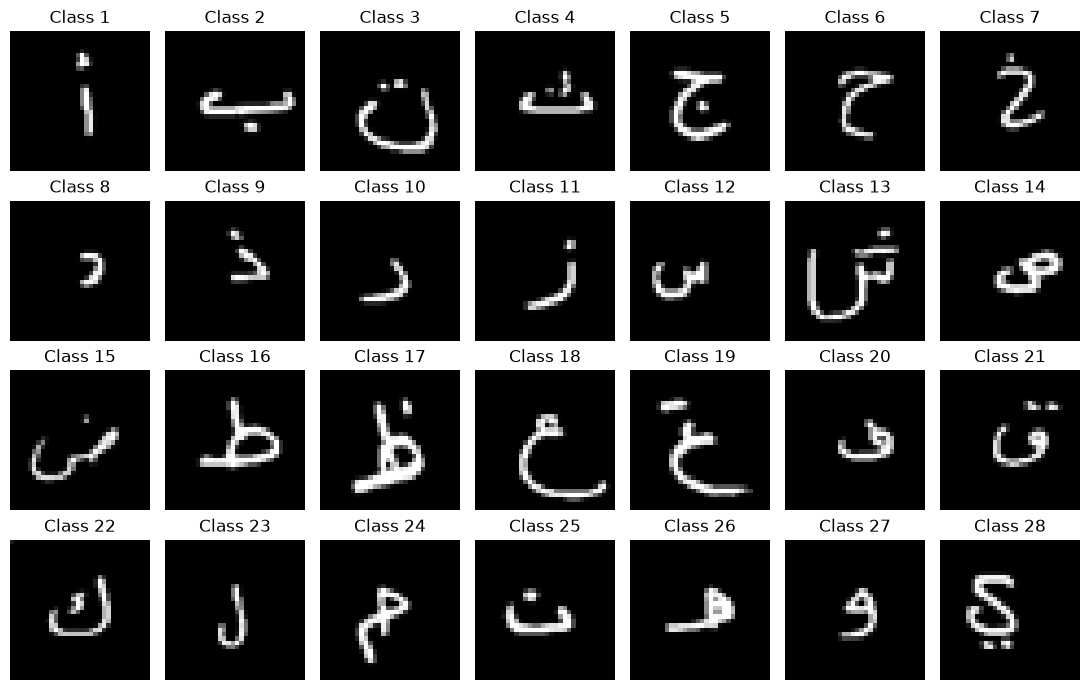

In [3]:
# Show one fitting image for each of the 28 classes to check appearance and orientation.
fig, axes = plt.subplots(4, 7, figsize=(11, 7))

for class_id, ax in enumerate(axes.flat):

    # Select the first fitting image with this internal class label.
    example_index = np.flatnonzero(y_train == class_id)[0]

    # Select channel 0 to display a two dimensional grayscale image.
    ax.imshow(X_train[example_index, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Class {label_mapping[str(class_id)]}")
    ax.axis("off")

plt.tight_layout()

plt.show()

## 3. Build the two block CNN

The architecture follows the lab example's two 64 filter convolutional blocks and 128 unit dense layer. AHCD has 32 by 32 grayscale images and 28 classes. As in the example, convolutions use the default valid padding.

| Stage | Output per image |
| --- | --- |
| Input | 32 by 32 by 1 |
| Block 1 convolution and pooling | 15 by 15 by 64 |
| Block 2 convolution and pooling | 6 by 6 by 64 |
| Flatten | 2304 values |
| Hidden layer | 128 values |
| Classifier | 28 probabilities |

The final softmax produces class probabilities. Use sparse categorical cross entropy with its default probability input, not from_logits=True.

In [4]:
# Sequential passes each layer's output into the following layer.
# Input declares the AHCD dimensions without using a deprecated layer input_shape argument.
# All learned weights are freshly initialized. No pretrained model is loaded.
model = models.Sequential([
    tf.keras.Input(shape=(32, 32, 1)),

    # Block 1 matches the lab pattern: convolution with ReLU, followed by max pooling.
    # A three by three kernel learns local patterns. Valid padding reduces 32 to 30.
    # Sixty four filters produce 64 feature maps, then pooling reduces 30 to 15.
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2 combines patterns from the previous maps using another 64 learned filters.
    # Convolution reduces 15 to 13. Pooling then reduces 13 to 6 using its default stride.
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Flatten converts six by six by 64 feature maps into 2304 values for each image.
    # Dense combines those features. ReLU introduces a nonlinear hidden activation.
    layers.Flatten(),
    layers.Dense(128, activation="relu"),

    # Softmax converts 28 output scores into probabilities that sum to one per image.
    layers.Dense(28, activation="softmax")
])
model.summary()
parameter_count = model.count_params()

# Check one real mini batch without training. training=False uses inference behavior.
batch_probabilities = model(X_train[:64], training=False)
batch_loss = tf.keras.losses.SparseCategoricalCrossentropy()(y_train[:64], batch_probabilities)

assert batch_probabilities.shape == (64, 28)

assert np.isfinite(batch_loss.numpy())

assert np.allclose(tf.reduce_sum(batch_probabilities, axis=1).numpy(), 1.0)
print("Batch output shape:", tuple(batch_probabilities.shape))
print("Initial batch loss:", round(float(batch_loss), 4))

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼─────────────────────

## 4. Compile and train the baseline

- Compile and fit use the same Keras interface as the teaching example.
- Supply the agreed validation arrays explicitly. Validation examples do not update weights.
- Keep Adam, batch size 64 and a maximum of 30 epochs as the documented baseline protocol.
- A built in EarlyStopping callback restores the minimum validation loss weights.
- No dropout, augmentation or pretrained weights are used.

The lab example uses five epochs. The longer maximum and early stopping here are declared project choices, rather than exact copies of every tutorial setting.

In [5]:
# Record the protocol so teammates can compare configurations using matching settings.
settings = {
    "model": "Basic CNN without blank fitting images",
    "training_images": len(y_train),
    "validation_images": len(y_valid),
    "excluded_fitting_rows": removed_indices.tolist(),
    "training_filter": "exclude all-zero fitting images only",
    "framework": "TensorFlow/Keras",
    "seed": seed,
    "filters": [64, 64],
    "kernel_size": [3, 3],
    "padding": "valid",
    "dense_units": 128,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 64,
    "maximum_epochs": 30,
    "early_stopping_patience": 5,
    "selection_metric": "validation_loss",
    "dropout": False,
    "augmentation": False,
    "pretrained": False,
    "tensorflow_version": tf.__version__,
    "keras_version": tf.keras.__version__
}

display(pd.DataFrame([settings]))

,model,training_images,validation_images,excluded_fitting_rows,training_filter,framework,seed,filters,kernel_size,padding,dense_units,optimizer,learning_rate,batch_size,maximum_epochs,early_stopping_patience,selection_metric,dropout,augmentation,pretrained,tensorflow_version,keras_version
0,Basic CNN without blank fitting images,10751,2688,[6050],exclude all-zero fitting images only,TensorFlow/Keras,42,"[64, 64]","[3, 3]",valid,128,Adam,0.001,64,30,5,validation_loss,False,False,False,2.21.0,3.15.1


In [6]:
# Adam performs gradient based updates inside Keras fit.
# Sparse labels are integer class IDs, so there is no one hot encoding step.
# The model already applies softmax, matching the probability based loss used in the lab.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=settings["learning_rate"]),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Stop after five epochs without lower validation loss and restore the best weights.
# min_delta=0 accepts any decrease. The limit of 30 epochs is an upper bound.
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=settings["early_stopping_patience"],
    min_delta=0.0, restore_best_weights=True
)

In [7]:
# Each epoch visits the fitting data once in shuffled mini batches.
# Rerun the setup and architecture cells first if starting another run from random weights.
started = perf_counter()
history_object = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=settings["maximum_epochs"],
    batch_size=settings["batch_size"],
    shuffle=True,
    callbacks=[early_stopping],
    verbose=2
)
training_seconds = perf_counter() - started

# Keras returns lists of per epoch losses and accuracies in its History object.
# Find the retained epoch from validation loss, not from highest validation accuracy.
history = pd.DataFrame(history_object.history)
history.insert(0, "epoch", np.arange(1, len(history) + 1))
best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
print("Best validation loss epoch:", best_epoch)
print("Training seconds:", round(training_seconds, 2))

Epoch 1/30
168/168 - 5s - 28ms/step - accuracy: 0.4391 - loss: 1.8771 - val_accuracy: 0.6659 - val_loss: 1.0773
Epoch 2/30
168/168 - 4s - 26ms/step - accuracy: 0.7558 - loss: 0.7564 - val_accuracy: 0.8088 - val_loss: 0.6137
Epoch 3/30
168/168 - 4s - 25ms/step - accuracy: 0.8505 - loss: 0.4622 - val_accuracy: 0.8419 - val_loss: 0.4963
Epoch 4/30
168/168 - 4s - 25ms/step - accuracy: 0.9008 - loss: 0.3099 - val_accuracy: 0.8624 - val_loss: 0.4431
Epoch 5/30
168/168 - 4s - 25ms/step - accuracy: 0.9329 - loss: 0.2157 - val_accuracy: 0.8709 - val_loss: 0.4381
Epoch 6/30
168/168 - 4s - 26ms/step - accuracy: 0.9530 - loss: 0.1577 - val_accuracy: 0.8612 - val_loss: 0.4721
Epoch 7/30
168/168 - 4s - 26ms/step - accuracy: 0.9594 - loss: 0.1328 - val_accuracy: 0.8757 - val_loss: 0.4780
Epoch 8/30
168/168 - 4s - 26ms/step - accuracy: 0.9594 - loss: 0.1283 - val_accuracy: 0.8497 - val_loss: 0.5561
Epoch 9/30
168/168 - 4s - 26ms/step - accuracy: 0.9674 - loss: 0.1005 - val_accuracy: 0.8683 - val_loss:

## 5. Inspect training curves

- Loss is the quantity minimized during training. Lower validation loss determines the retained epoch.
- A widening gap between fitting and validation performance can suggest overfitting.
- The curves include every attempted epoch, while the retained model uses the best validation weights.

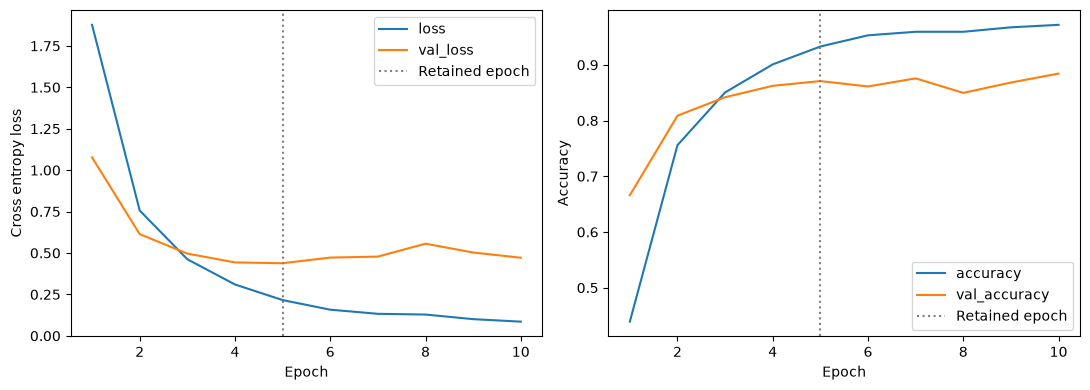

In [8]:
# The History column names match those produced by Keras fit in the lab example.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history.plot(x="epoch", y=["loss", "val_loss"], ax=axes[0])
history.plot(x="epoch", y=["accuracy", "val_accuracy"], ax=axes[1])
axes[0].set_ylabel("Cross entropy loss")
axes[1].set_ylabel("Accuracy")

for ax in axes:

    # Mark the epoch whose restored weights are used for the results below.
    ax.axvline(best_epoch, color="gray", linestyle=":", label="Retained epoch")
    ax.set_xlabel("Epoch")
    ax.legend()

plt.tight_layout()

plt.show()

## 6. Share validation results

- Accuracy is the proportion of validation images recognized correctly.
- Macro F1 gives equal importance to each character class.
- The confusion matrix is a validation diagnostic. It is not the final test confusion matrix requested for the eventual winning model.
- These numbers describe one seed on the fixed split. They do not establish statistical superiority over another model.

,model,framework,split,seed,accuracy,macro_f1,loss,best_epoch,epochs_run,parameters,training_seconds
0,Basic CNN without blank fitting images,TensorFlow/Keras,validation,42,0.8709,0.871,0.4381,5,10,336220,43.5991


,precision,recall,f1-score,support
1,0.979,0.979,0.979,96.000
2,0.929,0.948,0.938,96.000
3,0.753,0.729,0.741,96.000
4,0.880,0.760,0.816,96.000
5,0.855,0.979,0.913,96.000
6,0.857,0.812,0.834,96.000
7,0.759,0.854,0.804,96.000
8,0.869,0.896,0.882,96.000
9,0.963,0.823,0.888,96.000
10,0.778,0.948,0.854,96.000


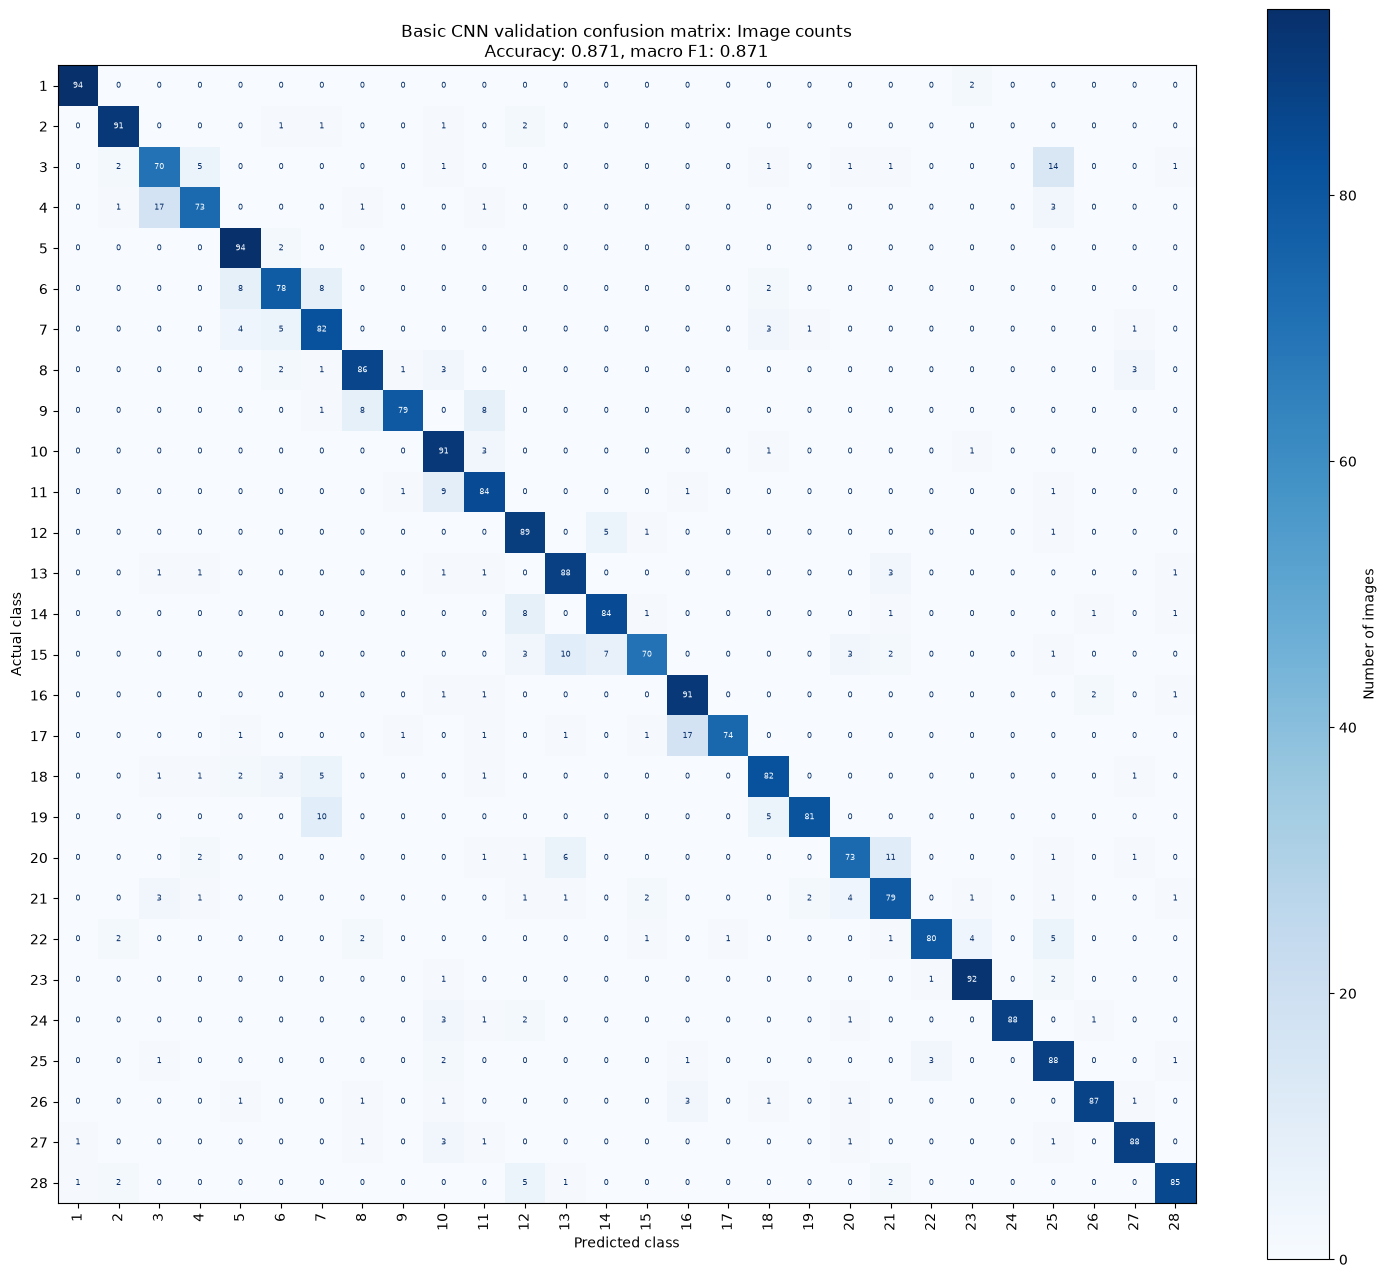

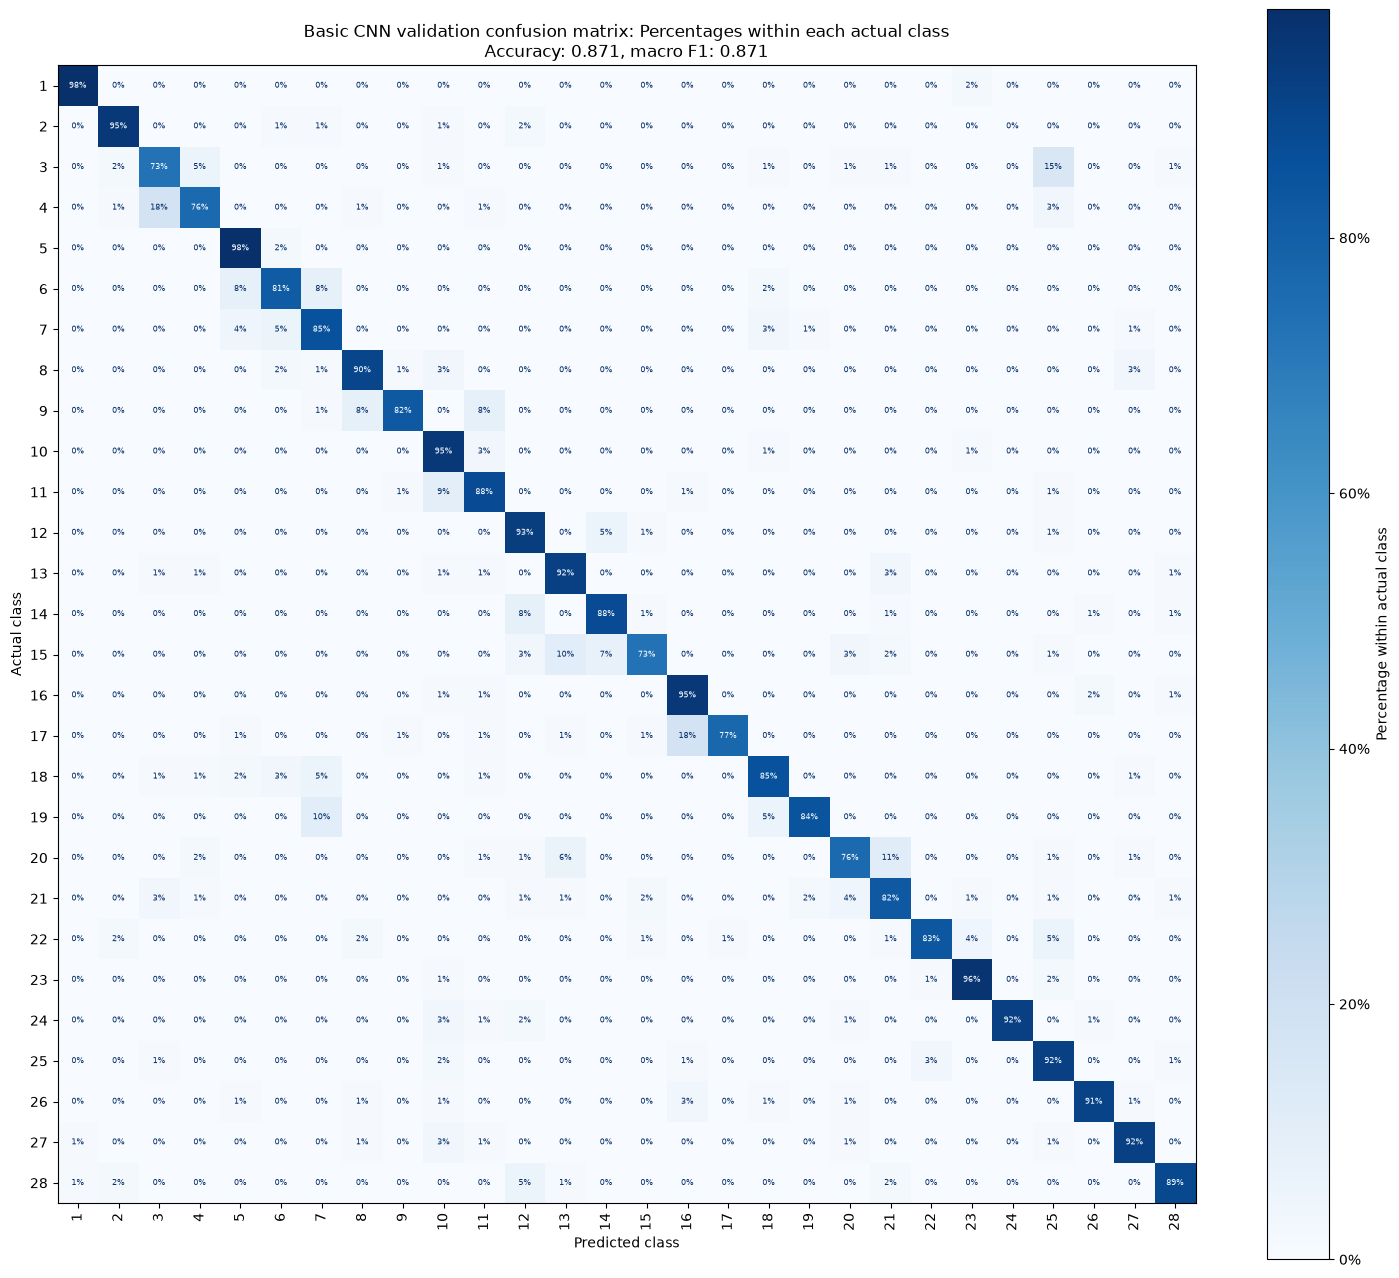

In [9]:
# predict returns one vector of 28 probabilities per validation image.
# argmax selects the internal label associated with the highest probability.
validation_probabilities = model.predict(X_valid, verbose=0)
validation_predictions = validation_probabilities.argmax(axis=1)

# Evaluate the restored model because the final history row may belong to a later epoch.
validation_loss, validation_accuracy = model.evaluate(X_valid, y_valid, verbose=0)
result = {
    "model": settings["model"],
    "framework": settings["framework"],
    "split": "validation",
    "seed": seed,
    "accuracy": accuracy_score(y_valid, validation_predictions),
    "macro_f1": f1_score(y_valid, validation_predictions, average="macro", zero_division=0),
    "loss": float(validation_loss),
    "best_epoch": best_epoch,
    "epochs_run": len(history),
    "parameters": parameter_count,
    "training_seconds": training_seconds
}

# Rounding changes the displayed table, not the precision of saved results.
display(pd.DataFrame([result]).round(4))
class_names = [str(label_mapping[str(i)]) for i in range(28)]

# Show per class precision, recall, F1 and the number of actual examples.
# Give a defined score of zero if a class receives no predicted examples.
report = classification_report(
    y_valid,
    validation_predictions,
    labels=np.arange(28),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

# Transpose puts characters on rows and metrics on columns.
report_table = pd.DataFrame(report).transpose()

display(report_table.round(3))

# Show the exact number of images in each cell, as in the teaching example.
# A separate normalized view shows the percentage within each actual class.
# Use large figures and small labels because AHCD has 28 classes rather than nine.
matrix_views = [
    {
        "normalization": None,
        "number_format": "d",
        "description": "Image counts",
        "filename": "confusion_matrix_counts.png",
    },
    {
        "normalization": "true",
        "number_format": ".0%",
        "description": "Percentages within each actual class",
        "filename": "confusion_matrix_percentages.png",
    },
]

for view in matrix_views:
    fig, ax = plt.subplots(figsize=(15, 13))
    matrix_display = ConfusionMatrixDisplay.from_predictions(
        y_valid, validation_predictions,
        labels=np.arange(28), display_labels=class_names,
        normalize=view["normalization"],
        include_values=True,
        values_format=view["number_format"],
        text_kw={"fontsize": 6}, cmap="Blues", xticks_rotation=90, ax=ax
    )

    # Use matching units inside the cells and on the color bar.
    # Text switches color for contrast. Cell backgrounds encode the values.
    if view["normalization"] == "true":
        colorbar = matrix_display.im_.colorbar
        colorbar.ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        colorbar.set_label("Percentage within actual class")
    else:
        matrix_display.im_.colorbar.set_label("Number of images")
    ax.set_title(
        f"Basic CNN validation confusion matrix: {view['description']}\n"
        f"Accuracy: {result['accuracy']:.3f}, macro F1: {result['macro_f1']:.3f}"
    )
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    plt.tight_layout()

    # Save a large image so teammates can zoom in without rerunning training.
    fig.savefig(output_folder / view["filename"], dpi=150, bbox_inches="tight")

    plt.show()

## 7. Compare training and validation using the retained model

- Evaluate the restored best model on both subsets. Do not combine training history from a later epoch with validation results from the retained epoch.
- Compare accuracy, macro F1 and cross entropy loss. A large training advantage can indicate overfitting.
- Training scores describe already seen examples, while validation scores describe the held out validation images.
- This diagnostic does not change weights, select another epoch or access the test set.

Training minus validation accuracy, percentage points: 7.13


,images,loss,accuracy,macro_f1
split,,,,
Training,10751,0.1767,0.9422,0.9423
Validation,2688,0.4381,0.8709,0.8710


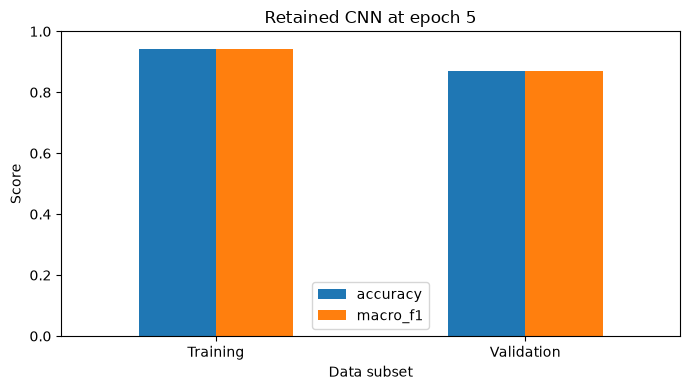

In [10]:
# Evaluate the same retained weights on fitting and validation data.
# evaluate and predict run inference without optimizer updates.
training_loss, training_accuracy = model.evaluate(X_train, y_train, verbose=0)
training_predictions = model.predict(X_train, verbose=0).argmax(axis=1)
training_macro_f1 = f1_score(
    y_train, training_predictions, average="macro", zero_division=0
)
training_validation_summary = pd.DataFrame([
    {"split": "Training", "images": len(y_train), "loss": training_loss,
     "accuracy": training_accuracy, "macro_f1": training_macro_f1},
    {"split": "Validation", "images": len(y_valid), "loss": result["loss"],
     "accuracy": result["accuracy"], "macro_f1": result["macro_f1"]}
]).set_index("split")

display(training_validation_summary.round(4))

# Store the accuracy gap as a difference in proportions, rather than a confidence interval.
result["training_accuracy"] = float(training_accuracy)
result["training_macro_f1"] = float(training_macro_f1)
result["training_loss"] = float(training_loss)
result["training_minus_validation_accuracy"] = float(training_accuracy - result["accuracy"])
print("Training minus validation accuracy, percentage points:",
      round(100 * result["training_minus_validation_accuracy"], 2))

# The same axis range makes comparisons between teammates' plots more straightforward.
ax = training_validation_summary[["accuracy", "macro_f1"]].plot.bar(
    figsize=(7, 4), ylim=(0, 1), rot=0
)
ax.set(xlabel="Data subset", ylabel="Score", title=f"Retained CNN at epoch {best_epoch}")

plt.tight_layout()
plt.savefig(output_folder / "training_validation_scores.png", dpi=150, bbox_inches="tight")

plt.show()

## 8. Compare recall across characters

- Recall measures the fraction of actual images of each character that were correctly recognized.
- Use original class numbers in a fixed order so the other four models can use an identical axis.
- This plot presents information already in the classification report in an easier to compare form.

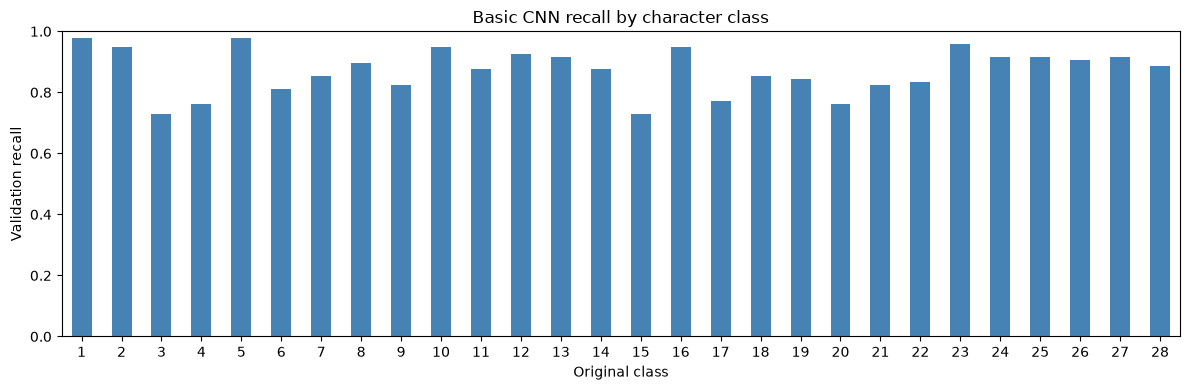

In [11]:
# Extract the existing report rather than calculating each class metric manually.
metric_columns = ["precision", "recall", "f1-score", "support"]
per_class_metrics = report_table.loc[class_names, metric_columns].copy()
per_class_metrics.index.name = "original_class"
ax = per_class_metrics["recall"].plot.bar(figsize=(12, 4), ylim=(0, 1), rot=0, color="steelblue")
ax.set(xlabel="Original class", ylabel="Validation recall", title="Basic CNN recall by character class")

plt.tight_layout()
plt.savefig(output_folder / "recall_by_class.png", dpi=150, bbox_inches="tight")

plt.show()

## 9. Inspect fixed diagnostic examples

Reuse the published shared example IDs for consistent image comparisons. They were selected from an earlier baseline's mistakes and may be correctly predicted by this filtered model. They are a diagnostic selection, not a representative performance sample.

,original_training_index,actual_class,predicted_class,predicted_probability
0,3188,7,7,0.988
1,13285,9,11,0.680
2,533,11,10,0.971
3,8184,16,16,0.880
4,4137,14,12,0.557
5,4413,20,13,0.914
6,7385,28,2,0.394
7,7200,5,5,0.770
8,1881,12,12,0.999
9,1611,6,7,0.518


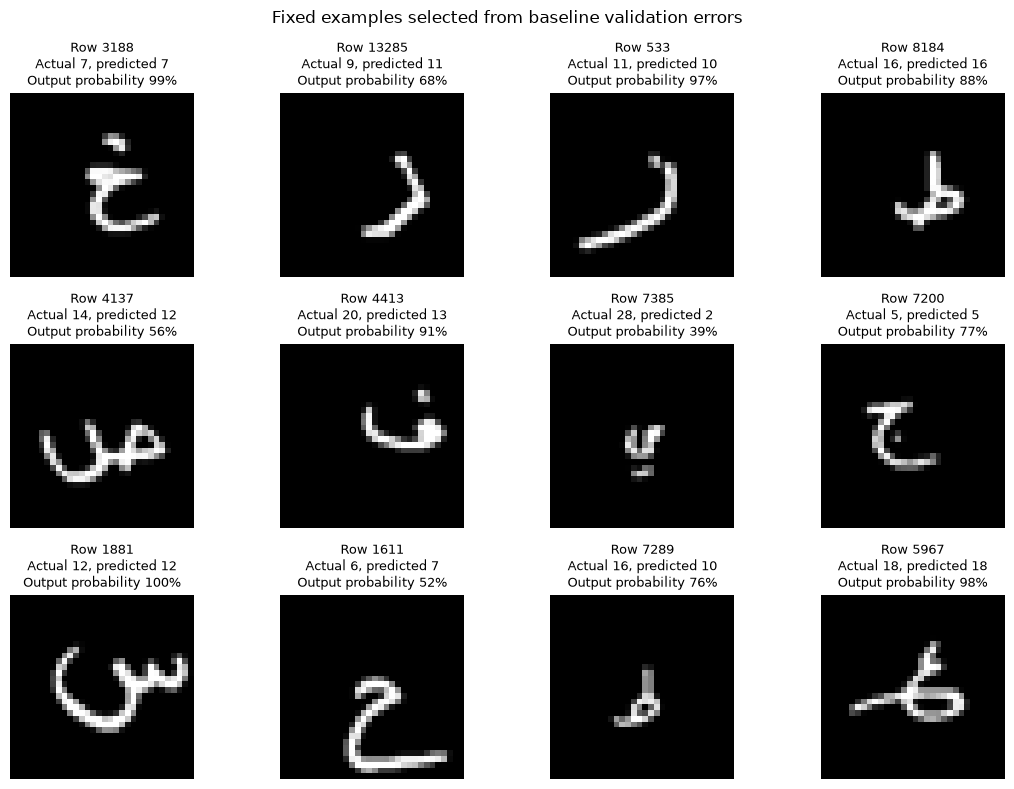

In [12]:
# Save original row IDs in the shared folder so every teammate can inspect the same images.
example_file = shared_folder / "baseline_mistake_indices.npz"

if example_file.exists():

    # Keep the first published example selection rather than choosing new favorable examples.
    with np.load(example_file, allow_pickle=False) as examples:
        example_row_indices = examples["original_training_indices"]
    example_positions = pd.Index(validation_indices).get_indexer(example_row_indices)

    assert (example_positions >= 0).all()
else:
    error_positions = np.flatnonzero(validation_predictions != y_valid)
    example_positions = np.random.default_rng(seed).choice(
        error_positions, size=min(12, len(error_positions)), replace=False
    )
    example_row_indices = validation_indices[example_positions]
    np.savez_compressed(example_file, original_training_indices=example_row_indices)

# Record identifiers and predictions so comparisons can refer to the exact same images.
example_table = pd.DataFrame({
    "original_training_index": example_row_indices,
    "actual_class": y_valid[example_positions] + 1,
    "predicted_class": validation_predictions[example_positions] + 1,
    "predicted_probability": validation_probabilities[example_positions].max(axis=1)
})

display(example_table.round(3))

fig, axes = plt.subplots(3, 4, figsize=(11, 8))

for ax in axes.flat:
    ax.axis("off")

for ax, position in zip(axes.flat, example_positions):
    ax.imshow(X_valid[position, :, :, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(
        f"Row {validation_indices[position]}\n"
        f"Actual {y_valid[position] + 1}, predicted {validation_predictions[position] + 1}\n"
        f"Output probability {validation_probabilities[position].max():.0%}", fontsize=9
    )

plt.suptitle("Fixed shared diagnostic examples")

plt.tight_layout()
plt.savefig(output_folder / "baseline_mistake_examples.png", dpi=150, bbox_inches="tight")

plt.show()

## 10. Summarize the most frequent confusions

- Count directional errors, such as actual class 3 being predicted as class 4.
- Exclude correct predictions on the diagonal and show the ten largest nonzero error counts.
- The table condenses the confusion matrix without introducing another evaluation metric.

In [13]:
# Calculate counts with the library function, then label the rows and columns.
counts_matrix = confusion_matrix(y_valid, validation_predictions, labels=np.arange(28))
counts_table = pd.DataFrame(
    counts_matrix,
    index=np.arange(1, 29),
    columns=np.arange(1, 29),
)
counts_table.index.name = "actual_class"
counts_table.columns.name = "predicted_class"

# stack converts the matrix into one row per actual and predicted class pair.
pairs = counts_table.stack().rename("images").reset_index()

# Keep only mistakes that occurred at least once.
is_mistake = pairs["actual_class"] != pairs["predicted_class"]
has_examples = pairs["images"] > 0
mistakes = pairs.loc[is_mistake & has_examples]

# Use class numbers to resolve tied counts in a reproducible order.
top_confusions = mistakes.sort_values(
    ["images", "actual_class", "predicted_class"],
    ascending=[False, True, True],
).head(10)

display(top_confusions.reset_index(drop=True))

,actual_class,predicted_class,images
0,4,3,17
1,17,16,17
2,3,25,14
3,20,21,11
4,15,13,10
5,19,7,10
6,11,10,9
7,6,5,8
8,6,7,8
9,9,8,8


## 11. Save the handover files

- Save the model in native Keras format with its architecture and weights.
- Save settings, epoch history, metrics, per class results, diagnostic tables and row aligned predictions.
- The other four experiments reuse the published split and have separate output folders.
- Select the final configuration using validation results before later final test evaluation.

In [14]:
# Native Keras saving retains the architecture, learned weights and optimizer state.
model.save(output_folder / "CNN.keras")
(output_folder / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")
(output_folder / "validation_results.json").write_text(json.dumps(result, indent=2) + "\n")
history.to_json(output_folder / "history.json", orient="records", indent=2)

# Save comparison ready diagnostic tables without exporting CSV files.
training_validation_summary.reset_index().to_json(
    output_folder / "training_validation_summary.json", orient="records", indent=2
)
per_class_metrics.reset_index().to_json(
    output_folder / "per_class_metrics.json", orient="records", indent=2
)
example_table.to_json(output_folder / "baseline_examples.json", orient="records", indent=2)
top_confusions.to_json(output_folder / "top_confusions.json", orient="records", indent=2)

# Original row indices let the team compare predictions on exactly matching images.
np.savez_compressed(output_folder / "validation_predictions.npz",
                    original_training_indices=validation_indices,
                    actual=y_valid, predicted=validation_predictions,
                    probabilities=validation_probabilities)

# Reload the actual saved model and check that its probabilities and classes agree.
restored_model = models.load_model(output_folder / "CNN.keras")
restored_probabilities = restored_model.predict(X_valid, verbose=0)

assert np.allclose(restored_probabilities, validation_probabilities, rtol=1e-5, atol=1e-6)

assert np.array_equal(restored_probabilities.argmax(axis=1), validation_predictions)
print("Saved model reproduces the validation predictions.")
print("Files saved in", output_folder)
print("The original test set was not loaded or evaluated in this notebook.")

Saved model reproduces the validation predictions.
Files saved in results
The original test set was not loaded or evaluated in this notebook.


## Recorded baseline results

- Training: 10,751 images after excluding one all-zero fitting image.
- Validation: the unchanged 2,688 shared rows.
- Accuracy: 87.09%. Macro F1: 0.8710. Cross-entropy: 0.4381.
- Early stopping completed at epoch 10 and restored epoch 5.
- Results and the trained model are in results/.

The filter follows the EDA quality finding. No shared files were rewritten. These are single-run validation scores, not final test scores.

## Next experiments and limitations

Use the same shared images, fitting-only blank-image filter and validation rows for subsequent Keras experiments. Change one assigned configuration and record its rationale. Save new experiments separately. Validation guides model selection and must remain outside gradient updates. Coordinate final testing with the team. A single run does not establish framework superiority, and the image-level validation split is not verified as writer-independent.

## References

- [Course P5.2 MLP and CNN teaching notebook](https://colab.research.google.com/drive/1W4DiEqH6HCNrUXM_UJsfo9Aq1j_rdFS6?usp=sharing)
- [AHCD dataset authors](https://github.com/mloey/Arabic-Handwritten-Characters-Dataset)
- [Selected AHCD dataset](https://www.kaggle.com/datasets/mloey1/ahcd1)
- [TensorFlow CNN tutorial linked by the course](https://www.tensorflow.org/tutorials/images/cnn)
- [Keras EarlyStopping](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping)

The two convolutional blocks, dense hidden layer and compile and fit format are adapted from the course example. Image size, output classes, saved data split, epoch limit, early stopping and handover files are project specific adaptations.